# How a Real Qubit Forgets: T₁ and T₂ from the Lindblad Equation

**Colin Casey, 2026.** SymPy derivations, numerical and Qiskit cross-checks, simulated lab experiments, and a short Lean section.

| Section | Question it answers |
|---|---|
| 1. The idea in plain English | What are T₁ and T₂, and why do they matter? |
| 2. The Lindblad equation in SymPy | What equation does a leaky qubit obey, element by element? |
| 3. Solving it exactly | Why $e^{-t/T_1}$, $e^{-t/T_2}$, and why $T_2 \le 2T_1$? |
| 4. The Bloch-vector picture | What do the equations look like as an arrow on a sphere? |
| 5. Two independent cross-checks | Does a 4×4 matrix exponential agree? Do Qiskit's Kraus maps agree? |
| 6. The experiments people actually run | T₁ inversion recovery, Ramsey (T₂*), Hahn echo, with shot noise and fits |
| 7. Temperature | Why qubits live at 20 mK |
| 8. From T₂ to error correction | Gate error ≈ t_gate / T₂, fed into the phase-flip code |
| 9. Lean 4 | A machine-checked inequality behind $T_2 \le 2T_1$ |

Kernel: **py312**.

In [1]:
import subprocess, pathlib
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.linalg import expm, null_space
from scipy.optimize import curve_fit
sp.init_printing(use_latex='mathjax')
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=OI), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

---
## 1. The idea in plain English

A perfect qubit would follow $e^{-iHt}$ forever. A real one is touched by its surroundings, and it forgets in two ways:

- **T₁, energy relaxation.** A qubit in $|1\rangle$ (the excited state) eventually drops to $|0\rangle$, giving its energy to the environment, like a hot cup of coffee cooling down. The chance it is still excited falls as $e^{-t/T_1}$.
- **T₂, dephasing.** A superposition $|0\rangle + e^{i\varphi}|1\rangle$ has a phase $\varphi$. Random kicks from the environment smear that phase out, so the "quantum" part (the coherence) fades as $e^{-t/T_2}$. Losing energy also destroys phase, so T₂ can never exceed 2T₁.

**Why an engineer cares:** a gate that takes $t_g$ fails with probability roughly $t_g/T_2$. Longer T₂, or faster gates, means fewer errors for error correction to fix. Illustrative scales: superconducting qubits have T₁, T₂ of about 0.1 ms with ~50 ns gates; trapped ions and neutral atoms reach seconds of T₂ with µs gates.

---
## 2. The Lindblad equation in SymPy

The state is a 2×2 **density matrix** $\rho = \begin{pmatrix}\rho_{00} & \rho_{01}\\ \rho_{10} & \rho_{11}\end{pmatrix}$: diagonal entries are probabilities, off-diagonal entries are coherences. The Lindblad (GKSL) master equation is the most general memoryless evolution that keeps $\rho$ a valid density matrix:
$$\dot\rho = -i[H,\rho] + \sum_k \left(L_k\rho L_k^\dagger - \tfrac12\{L_k^\dagger L_k,\rho\}\right)$$
with $H = -\tfrac{\omega}{2}\sigma_z$ (energy splitting $\omega$), relaxation $L_1 = \sqrt{\gamma_1}\,\sigma_-$ ($\sigma_- = |0\rangle\langle 1|$), and pure dephasing $L_\varphi = \sqrt{\gamma_\varphi/2}\,\sigma_z$.

In [2]:
t = sp.symbols('t', nonnegative=True)
w, g1, gp = sp.symbols('omega gamma_1 gamma_phi', positive=True)
r00, r11 = sp.Function('rho_00')(t), sp.Function('rho_11')(t)
r01 = sp.Function('rho_01')(t)
rho = sp.Matrix([[r00, r01], [sp.conjugate(r01), r11]])
sm = sp.Matrix([[0, 1], [0, 0]]); sz = sp.Matrix([[1, 0], [0, -1]])
H = -w/2*sz

def dissipator(L, r):
    return L*r*L.H - sp.Rational(1, 2)*(L.H*L*r + r*L.H*L)

rhs = (-sp.I*(H*rho - rho*H) + dissipator(sp.sqrt(g1)*sm, rho) + dissipator(sp.sqrt(gp/2)*sz, rho)).applyfunc(sp.simplify)
display(sp.Eq(sp.Symbol(r'\dot\rho_{11}'), rhs[1, 1]), sp.Eq(sp.Symbol(r'\dot\rho_{00}'), rhs[0, 0]), sp.Eq(sp.Symbol(r'\dot\rho_{01}'), rhs[0, 1]))
print('trace preserved, d(rho00 + rho11)/dt =', sp.simplify(rhs[0, 0] + rhs[1, 1]))
print('Hermiticity preserved: d(rho_10)/dt = conj(d(rho_01)/dt):', sp.simplify(rhs[1, 0] - sp.conjugate(rhs[0, 1])) == 0)
print('populations stay real: d(rho_11)/dt depends only on rho_11 with a real rate:', rhs[1, 1])

\dot\rho_{11} = -γ₁⋅ρ₁₁(t)

\dot\rho_{00} = γ₁⋅ρ₁₁(t)

                (-γ₁ - 2⋅γᵩ + 2⋅ⅈ⋅ω)⋅ρ₀₁(t)
\dot\rho_{01} = ───────────────────────────
                             2             

trace preserved, d(rho00 + rho11)/dt = 0
Hermiticity preserved: d(rho_10)/dt = conj(d(rho_01)/dt): True
populations stay real: d(rho_11)/dt depends only on rho_11 with a real rate: -gamma_1*rho_11(t)


---
## 3. Solving it exactly

The equations decouple: the excited population only decays, and the coherence decays while it rotates at $\omega$. SymPy's `dsolve` gives
$$\rho_{11}(t) = \rho_{11}(0)\,e^{-\gamma_1 t}, \qquad \rho_{01}(t) = \rho_{01}(0)\,e^{(i\omega - \gamma_1/2 - \gamma_\varphi)t}$$
so with $T_1 = 1/\gamma_1$ and $1/T_2 = \gamma_1/2 + \gamma_\varphi$:
$$\boxed{\frac{1}{T_2} = \frac{1}{2T_1} + \frac{1}{T_\varphi}} \quad\Rightarrow\quad T_2 \le 2T_1$$

In [3]:
P0, C0 = sp.symbols('P_1(0) rho_01(0)')
s11 = sp.dsolve(sp.Eq(sp.diff(r11, t), rhs[1, 1]), r11, ics={r11.subs(t, 0): P0}).rhs
s01 = sp.dsolve(sp.Eq(sp.diff(r01, t), rhs[0, 1]), r01, ics={r01.subs(t, 0): C0}).rhs
display(sp.Eq(sp.Symbol(r'\rho_{11}(t)'), s11), sp.Eq(sp.Symbol(r'\rho_{01}(t)'), sp.simplify(s01)))

T1, T2, Tp = sp.symbols('T_1 T_2 T_phi', positive=True)
decay = -sp.re(sp.expand(sp.log(sp.simplify(s01/C0))/t))          # coherence decay rate
display(sp.Eq(sp.Symbol('1/T_2'), decay.subs({g1: 1/T1, gp: 1/Tp})))
T2_expr = 1/(1/(2*T1) + 1/Tp)
print('T2 -> 2 T1 when there is no pure dephasing (T_phi -> oo):', sp.limit(T2_expr, Tp, sp.oo))
print('2 T1 - T2 >= 0 always:', sp.simplify(2*T1 - T2_expr), '  (numerator and denominator are positive)')

                      -γ₁⋅t
\rho_{11}(t) = P₁₍₀₎⋅ℯ     

                       -t⋅(γ₁ + 2⋅γᵩ - 2⋅ⅈ⋅ω) 
                       ───────────────────────
                                  2           
\rho_{01}(t) = ρ₀₁₍₀₎⋅ℯ                       

       1     1  
1/T₂ = ── + ────
       Tᵩ   2⋅T₁

T2 -> 2 T1 when there is no pure dephasing (T_phi -> oo): 2*T_1
2 T1 - T2 >= 0 always: 4*T_1**2/(2*T_1 + T_phi)   (numerator and denominator are positive)


---
## 4. The Bloch-vector picture

Any qubit state is an arrow $\vec r = (x, y, z)$ inside a unit sphere, with $x = 2\,\mathrm{Re}\,\rho_{01}$, $y = -2\,\mathrm{Im}\,\rho_{01}$, $z = \rho_{00} - \rho_{11}$. The Lindblad equation becomes the **Bloch equations** (Felix Bloch wrote them for nuclear spins in 1946; MRI still runs on them): the arrow precesses around $z$ at $\omega$, its length in the $xy$-plane shrinks at rate $1/T_2$, and $z$ relaxes to the ground state $+1$ at rate $1/T_1$.

In [4]:
xB = 2*sp.re(r01); yB = -2*sp.im(r01); zB = r00 - r11
d = {sp.Derivative(r00, t): rhs[0, 0], sp.Derivative(r11, t): rhs[1, 1], sp.Derivative(r01, t): rhs[0, 1],
     sp.Derivative(sp.conjugate(r01), t): sp.conjugate(rhs[0, 1])}
dz = sp.simplify(sp.diff(zB, t).subs(d).subs(r00, 1 - r11))
print('dz/dt with rho00 = 1 - rho11:'); display(sp.Eq(sp.Symbol(r'\dot z'), sp.factor(dz)))
print('-> equals -(z - 1)/T1 with z = 1 - 2 rho11:', sp.simplify(dz + ((1 - 2*r11) - 1)*g1) == 0)

dz/dt with rho00 = 1 - rho11:


\dot z = 2⋅γ₁⋅ρ₁₁(t)

-> equals -(z - 1)/T1 with z = 1 - 2 rho11: True


---
## 5. Two independent cross-checks

**(a) Superoperator.** Stack $\rho$ into a 4-vector; the Lindblad equation becomes $\dot{\vec\rho} = \mathcal L\vec\rho$ with a 4×4 matrix $\mathcal L$, solved by $e^{\mathcal L t}$.

**(b) Qiskit Kraus maps.** The same physics as a quantum channel: amplitude damping with $\gamma = 1 - e^{-t/T_1}$, then extra phase damping chosen so coherences decay as $e^{-t/T_2}$.

In [5]:
SM, SZ, I2 = np.array([[0, 1], [0, 0]], complex), np.diag([1.0, -1.0]).astype(complex), np.eye(2)

def liouvillian(omega, T1v, Tphiv=np.inf, gamma_up=0.0):
    Hm = -omega/2*SZ
    ops = [np.sqrt(1/T1v)*SM, np.sqrt((0 if np.isinf(Tphiv) else 1/Tphiv)/2)*SZ]
    if gamma_up: ops.append(np.sqrt(gamma_up)*SM.conj().T)
    L = -1j*(np.kron(I2, Hm) - np.kron(Hm.T, I2))
    for Lk in ops:
        LdL = Lk.conj().T @ Lk
        L += np.kron(Lk.conj(), Lk) - 0.5*(np.kron(I2, LdL) + np.kron(LdL.T, I2))
    return L

def evolve(rho0, tt, *args):
    return (expm(liouvillian(*args)*tt) @ rho0.reshape(-1, order='F')).reshape(2, 2, order='F')

omega_v, T1v, Tphiv = 2*np.pi*0.5, 40.0, 60.0                     # arbitrary units (e.g. microseconds)
T2v = 1/(1/(2*T1v) + 1/Tphiv)
plus = np.array([[0.5, 0.5], [0.5, 0.5]], complex)                  # |+><+|, P1 = 1/2, rho01 = 1/2
ts = np.linspace(0, 150, 31)
f11 = sp.lambdify(t, s11.subs({P0: 0.5, g1: 1/T1v}), 'numpy')
f01 = sp.lambdify(t, s01.subs({C0: 0.5, g1: 1/T1v, gp: 1/Tphiv, w: omega_v}), 'numpy')
err_a = max(max(abs(evolve(plus, tt, omega_v, T1v, Tphiv)[1, 1] - f11(tt)), abs(evolve(plus, tt, omega_v, T1v, Tphiv)[0, 1] - f01(tt))) for tt in ts)
print(f'(a) superoperator vs SymPy closed form, max difference: {err_a:.1e}')

from qiskit.quantum_info import Kraus, DensityMatrix
def qiskit_channel(tt, T1v, T2v):
    g = 1 - np.exp(-tt/T1v)
    amp = Kraus([np.array([[1, 0], [0, np.sqrt(1 - g)]]), np.array([[0, np.sqrt(g)], [0, 0]])])
    lam = 1 - (np.exp(-tt/T2v)/np.exp(-tt/(2*T1v)))**2
    ph = Kraus([np.array([[1, 0], [0, np.sqrt(1 - lam)]]), np.array([[0, 0], [0, np.sqrt(lam)]])])
    return amp.compose(ph)
err_b = 0.0
for tt in ts:
    rq = DensityMatrix(plus).evolve(qiskit_channel(tt, T1v, T2v)).data
    rl = evolve(plus, tt, 0.0, T1v, Tphiv)                          # omega = 0: compare in the rotating frame
    err_b = max(err_b, np.abs(rq - rl).max())
print(f'(b) Qiskit Kraus channel vs Lindblad (rotating frame), max difference: {err_b:.1e}')
print(f'    T1 = {T1v}, T_phi = {Tphiv}  ->  T2 = {T2v:.2f} <= 2 T1 = {2*T1v}')

(a) superoperator vs SymPy closed form, max difference: 2.1e-14


(b) Qiskit Kraus channel vs Lindblad (rotating frame), max difference: 4.4e-16
    T1 = 40.0, T_phi = 60.0  ->  T2 = 34.29 <= 2 T1 = 80.0


---
## 6. The experiments people actually run

Real hardware gives counts, not probabilities: each point below is 500 shots (binomial noise).

- **T₁ inversion recovery:** prepare $|1\rangle$, wait $\tau$, measure. $P_1(\tau) = e^{-\tau/T_1}$.
- **Ramsey (T₂\*):** $\pi/2$, wait $\tau$, $\pi/2$, measure. Oscillates at the detuning $\Delta$ and decays. Slow random drifts of the qubit frequency (different on every shot) add a Gaussian decay, so Ramsey measures $T_2^* < T_2$.
- **Hahn echo (T₂):** $\pi/2$, wait $\tau/2$, $\pi$, wait $\tau/2$, $\pi/2$. The $\pi$ pulse reverses the phase, so any *static* detuning cancels: the echo removes the drift and recovers the true $T_2$.

Fitting: a nonlinear fit of $Ae^{-\tau/T}+B$ gives T with an error bar. The tempting shortcut, a straight line through $\ln P$, is biased once $P$ approaches the shot-noise floor.

T1 true 40.0; one experiment: nonlinear fit 39.9 ± 0.5
over 200 repeated experiments: nonlinear mean 39.9 (spread 0.8),  log-linear mean 43.2 (spread 2.0)
-> near the noise floor the log-line keeps only the lucky nonzero points, which pulls its slope and T1 away from the truth
Ramsey: T2* = 7.5 ± 1.1, detuning 0.0810 (true 0.08)  -> shorter than T2: drift shortens it
Echo:   T2  = 34.9 ± 2.1  (true T2 = 34.3)  -> the pi pulse removed the drift


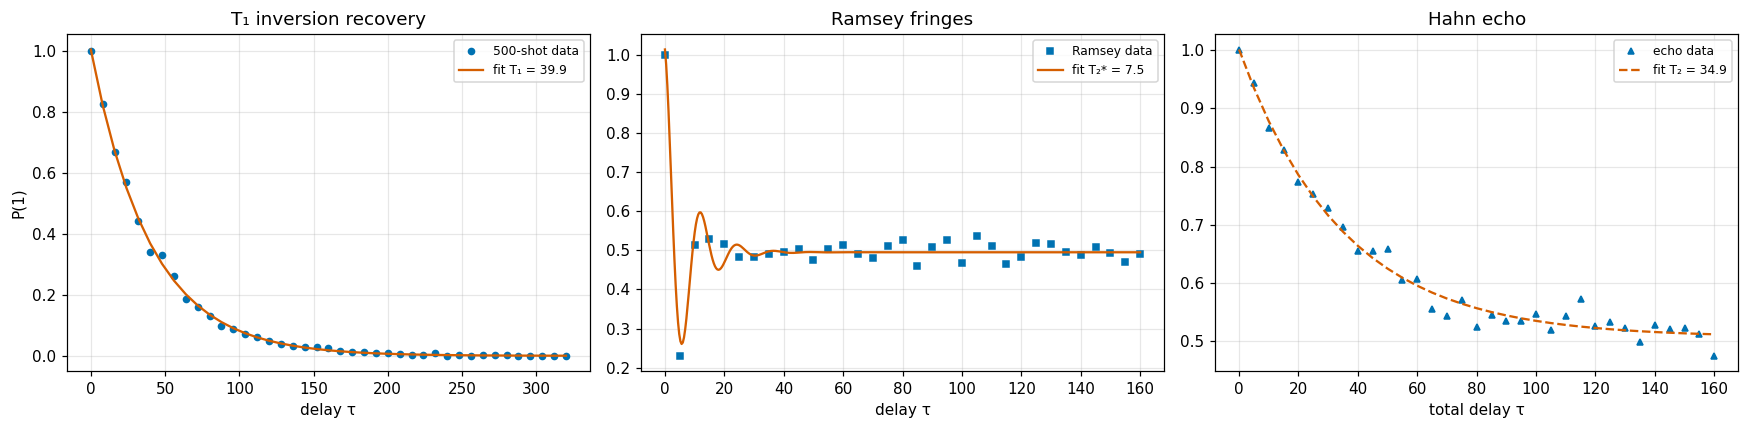

Figure: left, excited-state probability falls exponentially from 1 toward 0. Middle, Ramsey fringes oscillate and die out faster than the echo. Right, the echo decays smoothly from 1 toward 1/2 with the longer, true T2.


In [6]:
rng = np.random.default_rng(3)
shots = 500
tau = np.linspace(0, 160, 33)

# T1: delays out to 8 T1, where only a few of the 500 shots are still excited
tau1 = np.linspace(0, 320, 41)
exp_model = lambda x, A, T, B: A*np.exp(-x/T) + B
fits_nl, fits_log = [], []
for rep in range(200):                                              # repeat the experiment to see bias, not luck
    P1r = rng.binomial(shots, np.exp(-tau1/T1v))/shots
    fits_nl.append(curve_fit(exp_model, tau1, P1r, p0=(1, 30, 0))[0][1])
    keep = P1r > 0                                                  # log(0) is undefined: the zero points get dropped
    fits_log.append(-1/np.polyfit(tau1[keep], np.log(P1r[keep]), 1)[0])
P1_meas = rng.binomial(shots, np.exp(-tau1/T1v))/shots
(A_, T1_fit, B_), cov = curve_fit(exp_model, tau1, P1_meas, p0=(1, 30, 0))
print(f'T1 true {T1v}; one experiment: nonlinear fit {T1_fit:.1f} ± {np.sqrt(cov[1, 1]):.1f}')
print(f'over 200 repeated experiments: nonlinear mean {np.mean(fits_nl):.1f} (spread {np.std(fits_nl):.1f}),  '
      f'log-linear mean {np.mean(fits_log):.1f} (spread {np.std(fits_log):.1f})')
print('-> near the noise floor the log-line keeps only the lucky nonzero points, which pulls its slope and T1 away from the truth')

# Ramsey with quasi-static detuning noise, and Hahn echo
Delta, sigma_d, n_shots_detuning = 0.08, 0.02, 4000                # detuning and its shot-to-shot spread, in cycles per time unit
det = rng.normal(Delta, sigma_d, n_shots_detuning)
ramsey_true = np.array([0.5*(1 + np.exp(-tt/T2v)*np.mean(np.cos(2*np.pi*det*tt))) for tt in tau])
echo_true = 0.5*(1 + np.exp(-tau/T2v))                               # static detuning cancels exactly
ramsey = rng.binomial(shots, ramsey_true)/shots
echo = rng.binomial(shots, echo_true)/shots

ram_model = lambda x, T2s, D, A, B: A*np.exp(-x/T2s)*np.cos(2*np.pi*D*x) + B
(T2s_fit, D_fit, *_), cov_r = curve_fit(ram_model, tau, ramsey, p0=(30, 0.08, 0.5, 0.5))
(Ae, T2_fit, Be), cov_e = curve_fit(exp_model, tau, echo, p0=(0.5, 30, 0.5))
print(f'Ramsey: T2* = {T2s_fit:.1f} ± {np.sqrt(cov_r[0, 0]):.1f}, detuning {D_fit:.4f} (true {Delta})  -> shorter than T2: drift shortens it')
print(f'Echo:   T2  = {T2_fit:.1f} ± {np.sqrt(cov_e[1, 1]):.1f}  (true T2 = {T2v:.1f})  -> the pi pulse removed the drift')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(tau1, P1_meas, 'o', ms=4, label='500-shot data'); ax[0].plot(tau1, exp_model(tau1, A_, T1_fit, B_), '-', label=f'fit T₁ = {T1_fit:.1f}')
ax[0].set_title('T₁ inversion recovery'); ax[0].set_xlabel('delay τ'); ax[0].set_ylabel('P(1)'); ax[0].legend(fontsize=8)
ax[1].plot(tau, ramsey, 's', ms=4, label='Ramsey data'); tt_f = np.linspace(0, 160, 400)
ax[1].plot(tt_f, ram_model(tt_f, T2s_fit, D_fit, *_), '-', label=f'fit T₂* = {T2s_fit:.1f}')
ax[1].set_title('Ramsey fringes'); ax[1].set_xlabel('delay τ'); ax[1].legend(fontsize=8)
ax[2].plot(tau, echo, '^', ms=4, label='echo data'); ax[2].plot(tau, exp_model(tau, Ae, T2_fit, Be), '--', label=f'fit T₂ = {T2_fit:.1f}')
ax[2].set_title('Hahn echo'); ax[2].set_xlabel('total delay τ'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure: left, excited-state probability falls exponentially from 1 toward 0. Middle, Ramsey fringes oscillate '
      'and die out faster than the echo. Right, the echo decays smoothly from 1 toward 1/2 with the longer, true T2.')

---
## 7. Temperature: why qubits live at 20 mK

The environment can also *excite* the qubit, at a rate $\gamma_\uparrow = \gamma_\downarrow e^{-hf/k_BT}$ (detailed balance). The steady state then has a thermal excited population
$$P_1^{\text{eq}} = \frac{1}{1 + e^{hf/k_BT}}$$
The steady state is also the null vector of the Liouvillian, which gives an independent numerical check.

In [7]:
h_, kB = 6.62607015e-34, 1.380649e-23
P1_eq = lambda f, T: 1/(1 + np.exp(h_*f/(kB*T)))
for T_K in (0.010, 0.020, 0.050, 0.100, 4.0, 300.0):
    label = f'{T_K*1e3:.0f} mK' if T_K < 1 else f'{T_K:.0f} K'
    print(f'5 GHz qubit at {label:>7s}: thermal excited population {P1_eq(5e9, T_K):.2e}')
x_ = h_*5e9/(kB*0.05)
ss = null_space(liouvillian(1.0, 1.0, np.inf, np.exp(-x_)))[:, 0].reshape(2, 2, order='F'); ss /= np.trace(ss)
print(f'\nLiouvillian null vector at 50 mK: P1 = {ss[1, 1].real:.4e}   formula: {P1_eq(5e9, 0.05):.4e}')
print('At room temperature a 5 GHz qubit is ~50% excited: useless. At 20 mK it is ~6e-6 excited.')

5 GHz qubit at   10 mK: thermal excited population 3.79e-11
5 GHz qubit at   20 mK: thermal excited population 6.16e-06
5 GHz qubit at   50 mK: thermal excited population 8.17e-03
5 GHz qubit at  100 mK: thermal excited population 8.32e-02
5 GHz qubit at     4 K: thermal excited population 4.85e-01
5 GHz qubit at   300 K: thermal excited population 5.00e-01

Liouvillian null vector at 50 mK: P1 = 8.1687e-03   formula: 8.1687e-03
At room temperature a 5 GHz qubit is ~50% excited: useless. At 20 mK it is ~6e-6 excited.


---
## 8. From T₂ to error correction

During a gate of length $t_g$, dephasing scrambles the phase with probability $p = \tfrac12(1 - e^{-t_g/T_2}) \approx t_g/(2T_2)$. The 3-qubit phase-flip code (see `qiskit_phase_flip.ipynb`) turns that into $p_L = 3p^2 - 2p^3$. Illustrative superconducting numbers:

In [8]:
tg = sp.symbols('t_g', positive=True)
p_deph = (1 - sp.exp(-tg/T2))/2
display(sp.Eq(sp.Symbol('p'), p_deph))
print('for a short gate (t_g << T2):'); display(sp.Eq(sp.Symbol('p'), sp.series(p_deph, tg, 0, 2).removeO()))
for T2_us in (20, 80, 300):
    pv = float(p_deph.subs({tg: 50e-9, T2: T2_us*1e-6}))
    print(f'T2 = {T2_us:4d} us, 50 ns gate:  p = {pv:.2e}   ->  phase-flip code p_L = {3*pv**2 - 2*pv**3:.2e}')

         -t_g 
         ─────
          T₂  
    1   ℯ     
p = ─ - ──────
    2     2   

for a short gate (t_g << T2):


    t_g 
p = ────
    2⋅T₂

T2 =   20 us, 50 ns gate:  p = 1.25e-03   ->  phase-flip code p_L = 4.67e-06
T2 =   80 us, 50 ns gate:  p = 3.12e-04   ->  phase-flip code p_L = 2.93e-07
T2 =  300 us, 50 ns gate:  p = 8.33e-05   ->  phase-flip code p_L = 2.08e-08


---
## 9. Lean 4: the inequality behind $T_2 \le 2T_1$

In rates, $\Gamma_2 = 1/T_2$ and $\Gamma_1 = 1/T_1$, the relation is $2\Gamma_2 = \Gamma_1 + 2\Gamma_\varphi$. Rates are non-negative, so $2\Gamma_2 \ge \Gamma_1$, which is $T_2 \le 2T_1$. With rates measured as whole numbers of a small unit (e.g. per second), Lean proves it for every value, plus the equality case.

In [9]:
lean_src = r'''
-- 2 Γ₂ = Γ₁ + 2 Γ_φ with non-negative rates (natural numbers in some unit) implies 2 Γ₂ ≥ Γ₁, i.e. T₂ ≤ 2 T₁
theorem t2_le_two_t1 (g1 gphi g2 : Nat) (h : 2 * g2 = g1 + 2 * gphi) : g1 ≤ 2 * g2 := by omega
-- equality T₂ = 2 T₁ happens exactly when there is no pure dephasing
theorem t2_eq_two_t1_iff (g1 gphi g2 : Nat) (h : 2 * g2 = g1 + 2 * gphi) : (2 * g2 = g1 ↔ gphi = 0) := by omega
-- example from section 5: T₁ = 40, T_φ = 60 -> rates in units of 1/120: Γ₁ = 3, Γ_φ = 2, so 2 Γ₂ = 3 + 4 = 7
theorem example_rates : 2 * 7 = 2 * 3 + 2 * 4 ∧ 3 ≤ 7 := by decide
'''
lean_file = pathlib.Path.cwd() / 'lindblad_t1_t2.lean'
lean_file.write_text(lean_src.strip() + '\n', encoding='utf-8')
print(lean_src.strip())
r = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: exit code {r.returncode}')
print('✓ verified by the Lean kernel' if r.returncode == 0 else (r.stdout + r.stderr))

-- 2 Γ₂ = Γ₁ + 2 Γ_φ with non-negative rates (natural numbers in some unit) implies 2 Γ₂ ≥ Γ₁, i.e. T₂ ≤ 2 T₁
theorem t2_le_two_t1 (g1 gphi g2 : Nat) (h : 2 * g2 = g1 + 2 * gphi) : g1 ≤ 2 * g2 := by omega
-- equality T₂ = 2 T₁ happens exactly when there is no pure dephasing
theorem t2_eq_two_t1_iff (g1 gphi g2 : Nat) (h : 2 * g2 = g1 + 2 * gphi) : (2 * g2 = g1 ↔ gphi = 0) := by omega
-- example from section 5: T₁ = 40, T_φ = 60 -> rates in units of 1/120: Γ₁ = 3, Γ_φ = 2, so 2 Γ₂ = 3 + 4 = 7
theorem example_rates : 2 * 7 = 2 * 3 + 2 * 4 ∧ 3 ≤ 7 := by decide



lindblad_t1_t2.lean: exit code 0
✓ verified by the Lean kernel


---
## Summary

- The Lindblad equation keeps $\rho$ physical (trace and Hermiticity preserved, checked in SymPy).
- Its exact solution gives $e^{-t/T_1}$ for populations and $e^{-t/T_2}$ for coherences, with $1/T_2 = 1/(2T_1) + 1/T_\varphi$, so $T_2 \le 2T_1$.
- A 4×4 matrix exponential and Qiskit's Kraus channels agree with the closed form to machine precision.
- Experiments: T₁ from inversion recovery, T₂* from Ramsey (shortened by drift), T₂ from a Hahn echo; fit nonlinearly, not with a log-line near the noise floor.
- Temperature sets the thermal floor: a 5 GHz qubit needs millikelvin.
- Gate error ≈ t_g/(2T₂) is the number error correction has to beat.

*Numbers for specific hardware are illustrative.*

## References

[1] G. Lindblad, "On the generators of quantum dynamical semigroups," *Commun. Math. Phys.*, vol. 48, no. 2, pp. 119–130, 1976.

[2] F. Bloch, "Nuclear induction," *Phys. Rev.*, vol. 70, nos. 7–8, pp. 460–474, 1946.

[3] E. L. Hahn, "Spin echoes," *Phys. Rev.*, vol. 80, no. 4, pp. 580–594, 1950.

[4] P. Krantz, M. Kjaergaard, F. Yan, T. P. Orlando, S. Gustavsson, and W. D. Oliver, "A quantum engineer's guide to superconducting qubits," *Appl. Phys. Rev.*, vol. 6, no. 2, art. 021318, 2019.

[5] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. Cambridge, U.K.: Cambridge Univ. Press, 2010, ch. 8.

*Reference details written from memory; verify before citing.*